# Exploratory Data Analysis: Opportunity Atlas Outcome Dataset
First let's start with imports and loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

In [ ]:
# For Huy to load the data
from google.colab import drive
drive.mount('/content/drive/')

outcome_dr = '/content/drive/MyDrive/DATA 102 Final Project/EDA/outcomes.csv'

outcomes = pd.read_csv(outcome_dr)

KeyboardInterrupt: 

In [ ]:
# For loading the data if dataset was added manually to session
outcomes = pd.read_csv('outcomes.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'outcomes.csv'

In [ ]:
outcomes.info()

NameError: name 'outcomes' is not defined

### Data Pre-Processing
The original outcomes data contains a lot of data. We want to narrow our focus to California specific data and remove unnecessary and null columns so that we're only exploring the data relevant for our research.

In [ ]:
# Filter scope of data down to California and extract counties
outcomes[['county', 'state']] = outcomes['name'].str.split(', ', expand=True)
outcomes = outcomes[outcomes['state'] == 'CA']

# Select columns, rename them
outcomes = outcomes.loc[:, ['county', 'kfr_rP_gP_pall', 'kir_rP_gP_pall', 'spouse_rank_rP_gP_pall', 'working_rP_gP_pall', 'coll_rP_gP_pall']]
outcomes.rename(columns={'kfr_rP_gP_pall': 'Household_Income_at_Age_35', 'kir_rP_gP_pall': 'Individual_Income_Excluding_Spouse_at_Age_35', 'spouse_rank_rP_gP_pall': "Spouse's_Income_at_Age_35", 'working_rP_gP_pall': 'Employment_Rate_at_Age_35', 'coll_rP_gP_pall': 'College_Grad_Rate'}, inplace=True)

Finally we will handle NA values so the data is ready for use.

In [ ]:
rows_before = outcomes.shape[0]
outcomes.dropna(inplace=True) # Could impute NA rows as not to lose information, possibly predict missing values using regression on county characteristics, our covariates.
rows_after = outcomes.shape[0]
print(f'Rows dropped: {rows_before - rows_after}')

Rows dropped: 2


In [ ]:
outcomes.sort_values(by='county', ascending=True).head(5)

,county,Household_Income_at_Age_35,Individual_Income_Excluding_Spouse_at_Age_35,Spouse's_Income_at_Age_35,Employment_Rate_at_Age_35,College_Grad_Rate
568,Alameda County,48159.0,34219.0,44974.0,0.7720,0.4510
422,Amador County,47456.0,30957.0,38032.0,0.7470,0.3201
177,Butte County,41765.0,27749.0,38213.0,0.7298,0.3125
2937,Calaveras County,44152.0,28431.0,38629.0,0.7332,0.2647
2395,Colusa County,44294.0,29043.0,40260.0,0.7470,0.2785


In [ ]:
outcomes.to_csv('outcomes_processed.csv', index=False)

### Exploring the dataset
First we will compare columns to understand the relationships between them.

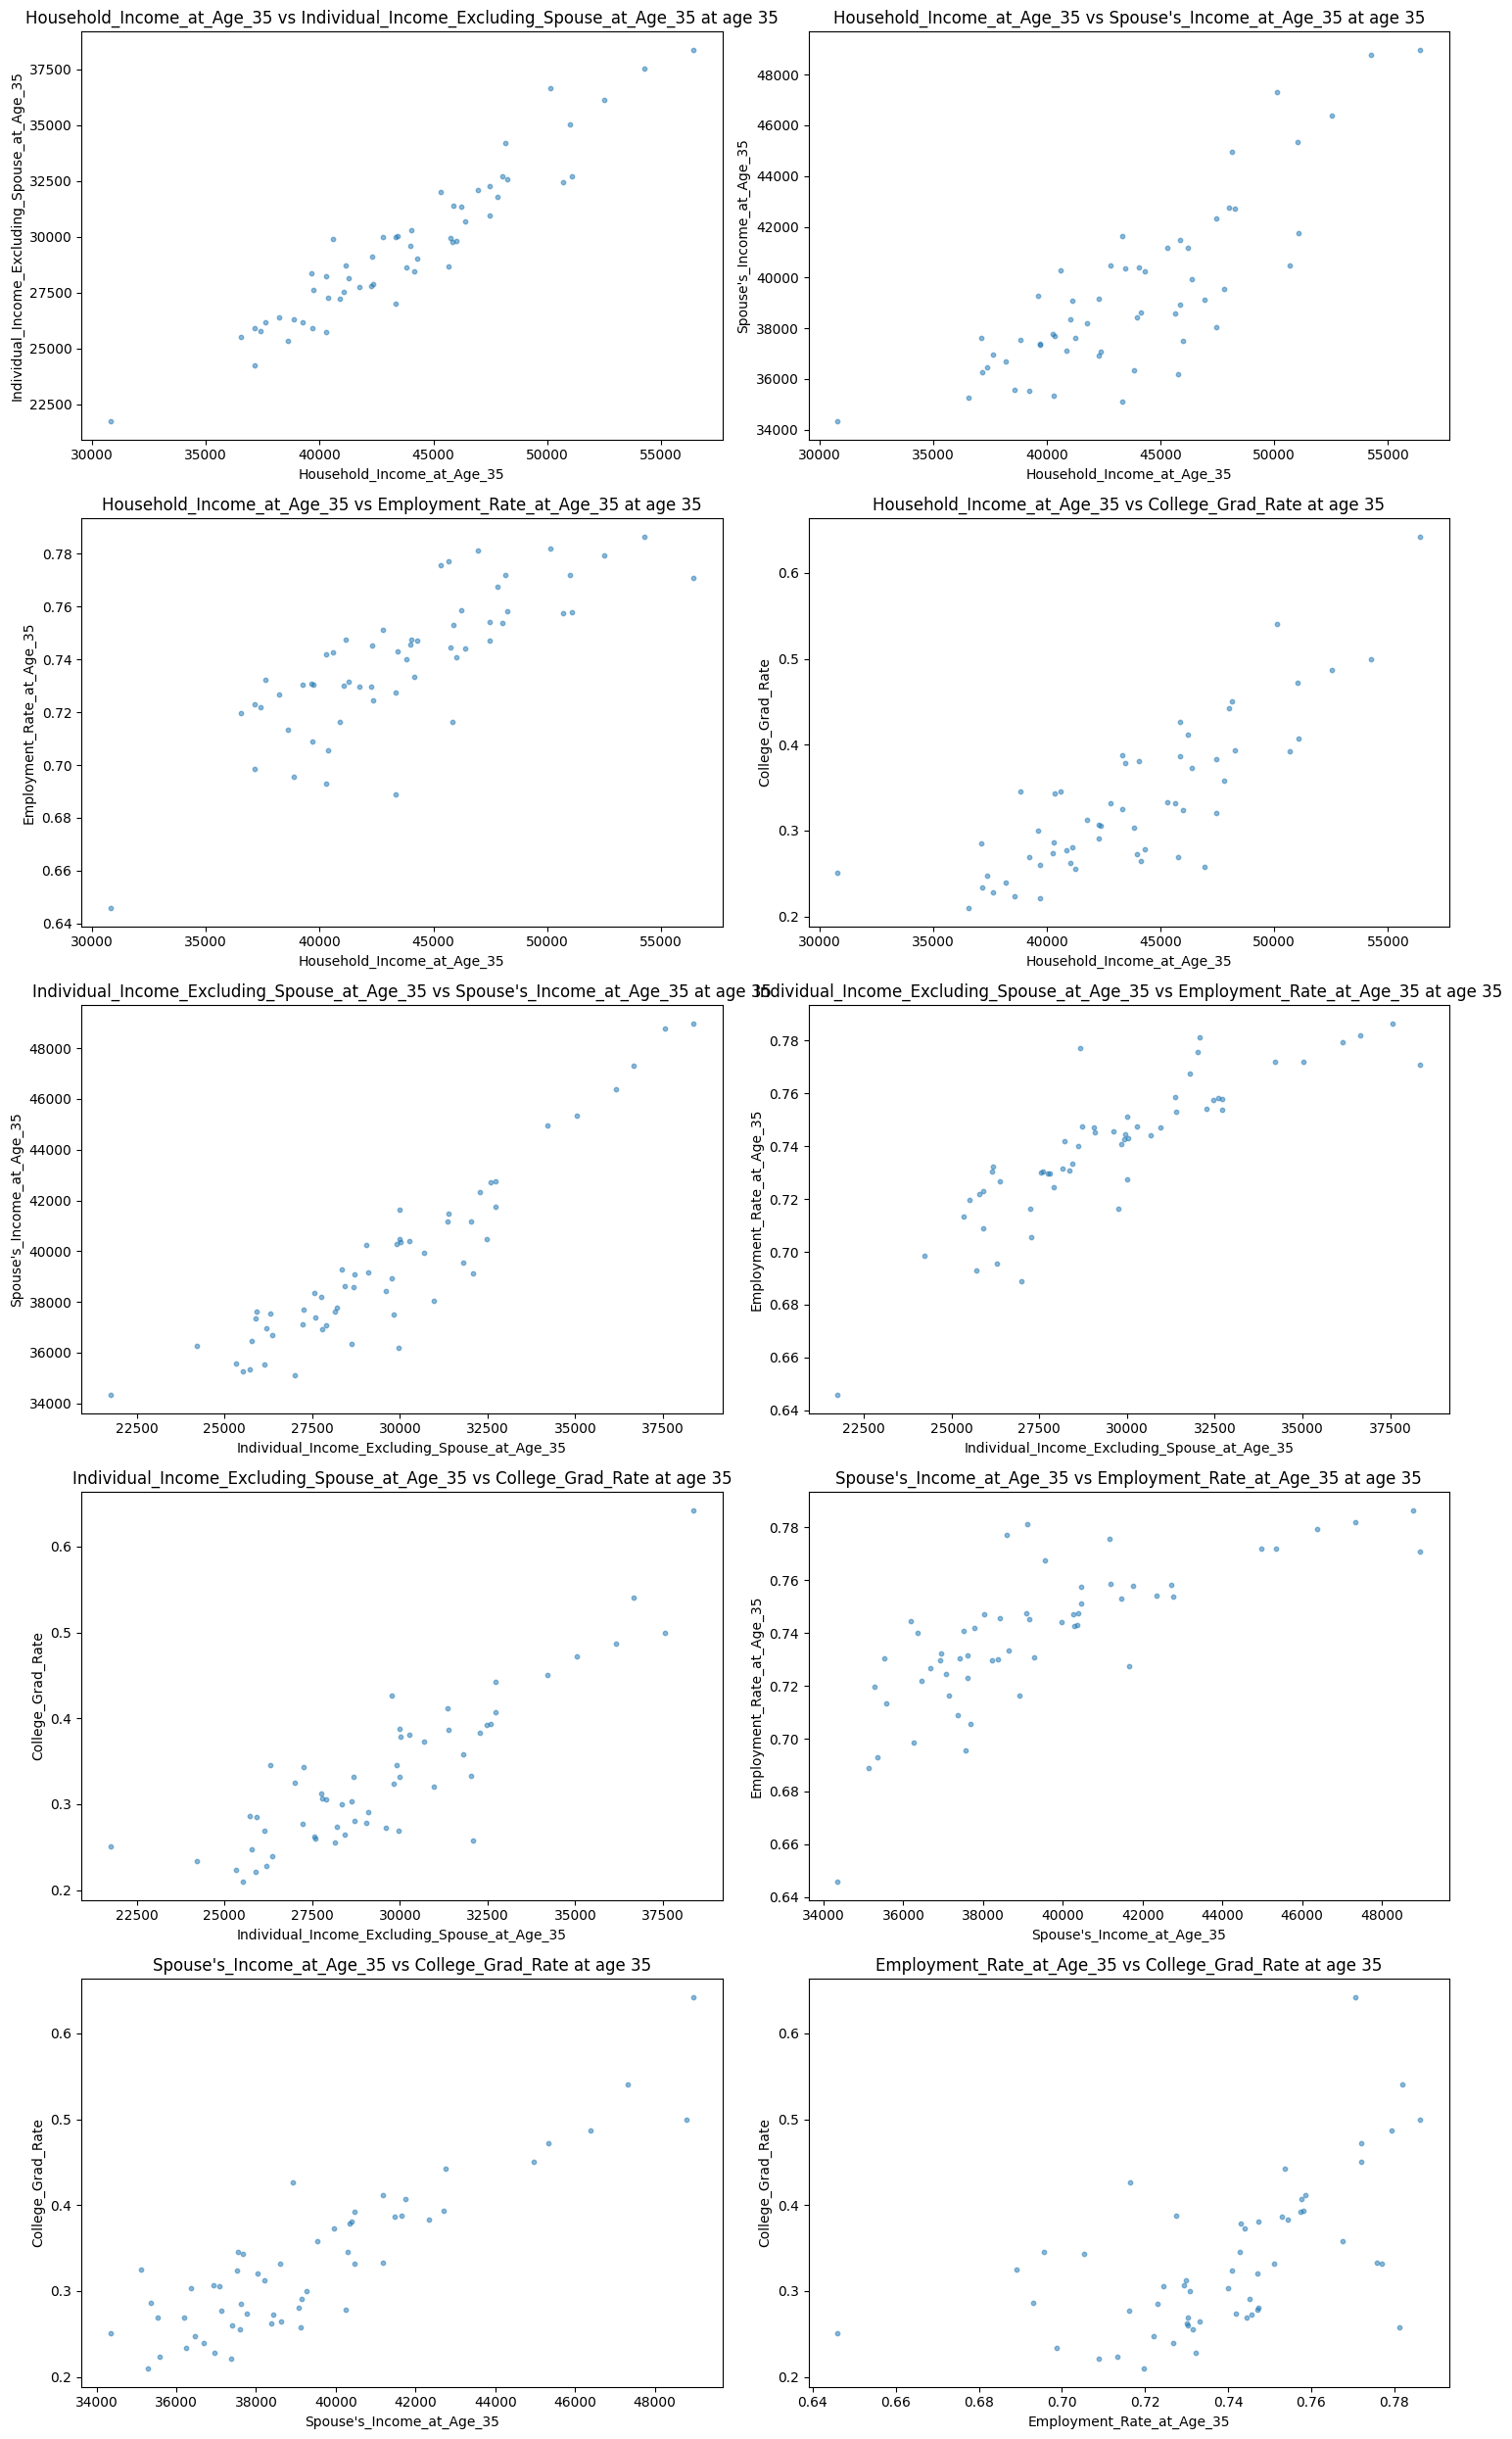

In [ ]:
numeric_columns = outcomes.drop(columns='county')
column_pairs = list(itertools.combinations(numeric_columns, 2))

num_plots = len(column_pairs)
num_cols = 2
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axs = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 5))
axs = axs.flatten()

for i, (col_x, col_y) in enumerate(column_pairs):
    axs[i].scatter(outcomes[col_x], outcomes[col_y], alpha=0.5, s=10)
    axs[i].set_xlabel(col_x)
    axs[i].set_ylabel(col_y)
    axs[i].set_title(f"{col_x} vs {col_y} at age 35")

for j in range(len(column_pairs), len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()

### Interpretting the results
Observing the graphs above, we noticed that:



*   All reported outcomes appear to be positively correlated. This could indicate shared causal variables or causal influences between outcomes. For example, individual income could have a causal influence on household income. Highly correlated outcomes can provide redundant information, so we may wish to only consider one of any two highly correlated outcomes in our research.

*   College graduation rate and employment rate outcomes per county appear to be most weakly related. These are two outcomes we might wish to further look into. This could indicate opportunities not strongly tied together.

*   Some additional observed patterns:
Counties where people ended up with higher household incomes had higher employment rate outcomes. College graduation rates were primarily distributed below 0.6 for all counties but still had a slight positive correlation with employment rate.

### Looking at distributions
Now let's take a look at distributions of some of the interesting outcomes.

In [ ]:
percentiles = outcomes['Individual_Income_Excluding_Spouse_at_Age_35'].quantile([0.25, 0.5, 0.75]).values
college_percentiles = outcomes['College_Grad_Rate'].quantile([0.25, 0.5, 0.75]).values
employment_percentiles = outcomes['Employment_Rate_at_Age_35'].quantile([0.25, 0.5, 0.75]).values
bins = [0, percentiles[0], percentiles[1], percentiles[2], outcomes['Individual_Income_Excluding_Spouse_at_Age_35'].max()]
college_bins = [0, college_percentiles[0], college_percentiles[1], college_percentiles[2], outcomes['College_Grad_Rate'].max()]
employment_bins = [0, employment_percentiles[0], employment_percentiles[1], employment_percentiles[2], outcomes['Employment_Rate_at_Age_35'].max()]
labels = ['0-25th', '25-50th', '50-75th', '75-100th']
outcomes['Income Bracket'] = pd.cut(outcomes['Individual_Income_Excluding_Spouse_at_Age_35'], bins=bins, labels=labels, include_lowest=True)
outcomes['College Grad Bracket'] = pd.cut(outcomes['College_Grad_Rate'], bins=college_bins, labels=labels, include_lowest=True)
outcomes['Employment Rate Bracket'] = pd.cut(outcomes['Employment_Rate_at_Age_35'], bins=employment_bins, labels=labels, include_lowest=True)
outcomes.head()

,county,Household_Income_at_Age_35,Individual_Income_Excluding_Spouse_at_Age_35,Spouse's_Income_at_Age_35,Employment_Rate_at_Age_35,College_Grad_Rate,Income Bracket,College Grad Bracket,Employment Rate Bracket
86,Mendocino County,38851.0,26300.0,37548.0,0.6956,0.3457,0-25th,50-75th,0-25th
112,Glenn County,39698.0,25897.0,37370.0,0.7089,0.2212,0-25th,0-25th,0-25th
113,Kings County,37629.0,26191.0,36946.0,0.7322,0.2283,0-25th,0-25th,25-50th
130,Imperial County,30813.0,21755.0,34353.0,0.6460,0.2512,0-25th,0-25th,0-25th
131,Siskiyou County,43827.0,28621.0,36364.0,0.7400,0.3032,25-50th,25-50th,25-50th


In [ ]:
low_income_count = (outcomes['Individual_Income_Excluding_Spouse_at_Age_35'] < np.mean(outcomes['Individual_Income_Excluding_Spouse_at_Age_35'])).sum()
high_income_count = (outcomes['Individual_Income_Excluding_Spouse_at_Age_35'] > np.mean(outcomes['Individual_Income_Excluding_Spouse_at_Age_35'])).sum()

low_college_grad_count = (outcomes['College_Grad_Rate'] < np.mean(outcomes['College_Grad_Rate'])).sum()
high_college_grad_count = (outcomes['College_Grad_Rate'] > np.mean(outcomes['College_Grad_Rate'])).sum()

print("Count of counties with Individual Income below the mean:", low_income_count)
print("Count of counties with Individual Income above the mean:", high_income_count)
print("Count of counties with College Grad Rate below the mean:", low_college_grad_count)
print("Count of counties with College Grad Rate above the mean:", high_college_grad_count)

Count of counties with Individual Income below the mean: 29
Count of counties with Individual Income above the mean: 27
Count of counties with College Grad Rate below the mean: 34
Count of counties with College Grad Rate above the mean: 22


### Observations comparing counties below and above the mean
One thing we noticed is that there is a bigger gap between the number of counties with college grad outcomes below the mean and higher than the mean than counties with individual income outcomes below and above the mean. Therefore, we want to know if the college graduation rate has a significant impact on individual income. We proceed to plot the unnormalized histogram distribution to examine further more.

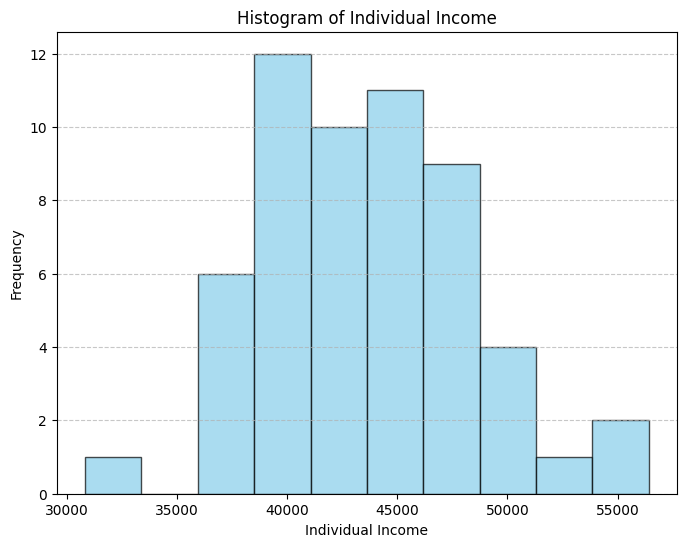

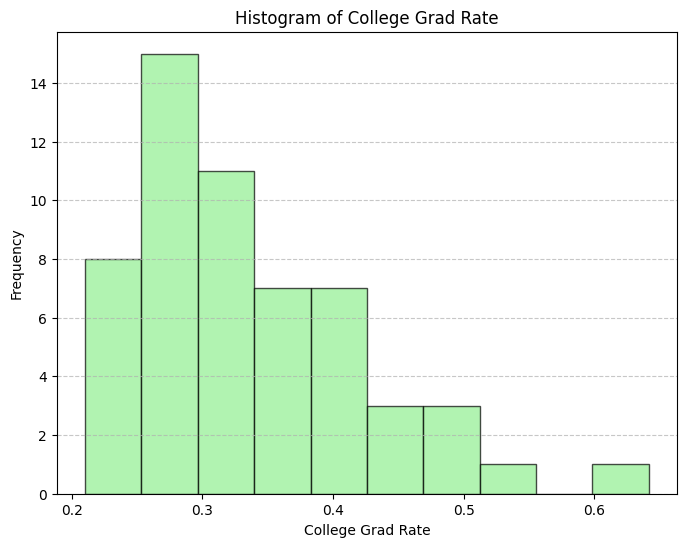

/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


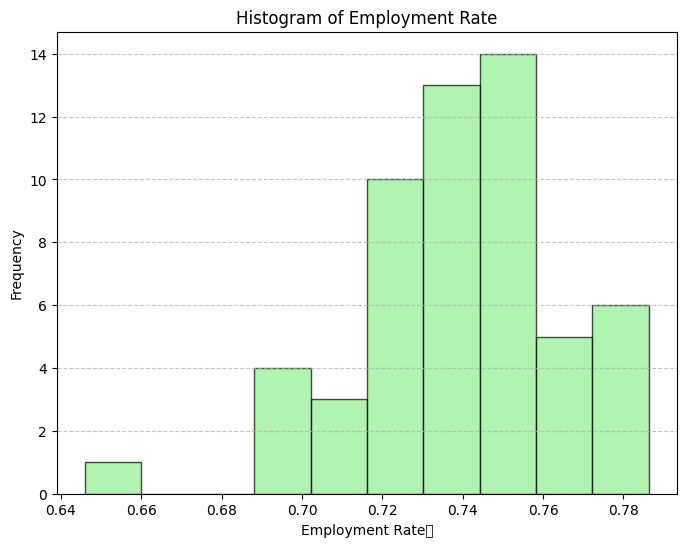

In [ ]:
plt.figure(figsize=(8, 6))
outcomes['Household_Income_at_Age_35'].plot(kind='hist', bins=10, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Individual Income')
plt.xlabel('Individual Income')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(8, 6))
outcomes['College_Grad_Rate'].plot(kind='hist', bins=10, color='lightgreen', edgecolor='black', alpha=0.7)
plt.title('Histogram of College Grad Rate')
plt.xlabel('College Grad Rate')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(8, 6))
outcomes['Employment_Rate_at_Age_35'].plot(kind='hist', bins=10, color='lightgreen', edgecolor='black', alpha=0.7)
plt.title('Histogram of Employment Rate')
plt.xlabel('Employment Rate	')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

We hypothesized that counties with higher College Grad Rate outcomes will have higher Employment Rate and higher Individual Incomes outcomes due to a causal relationship between employment and income. We expected that the distributions would therefore be similar, but we were surprised that all there were differently distributed and that Individual Income was not more skewed to the right like employment rate.

This leaves us with the question: Why is the above the case for California? Is there any other potential factor that we haven't consider? Could air quality affect the income?

### Finally, let's see what counties are at the top and bottom of the range of college graduation rates and employment rate.

In [ ]:
low_grad_county = outcomes[(outcomes['College Grad Bracket'] == '0-25th')]['county']
high_grad_county = outcomes[(outcomes['College Grad Bracket'] == '75-100th')]['county']
print("Counties with 0-25th percentile in College Grad: \n", low_grad_county)
print("Counties with 75th-100th percentile in College Grad: \n", high_grad_county)

Counties with 0-25th percentile in College Grad: 
 112          Glenn County
113          Kings County
130       Imperial County
208           Yuba County
251         Tulare County
276         Madera County
278         Tehama County
342      Del Norte County
364           Kern County
400         Merced County
533     Stanislaus County
567      Riverside County
2457          Mono County
2937     Calaveras County
Name: county, dtype: object
Counties with 75th-100th percentile in College Grad: 
 253    San Francisco County
359           Nevada County
476       Santa Cruz County
493             Yolo County
531           Sonoma County
568          Alameda County
585           Placer County
597        El Dorado County
603           Orange County
627     Contra Costa County
650          Ventura County
656      Santa Clara County
667        San Mateo County
705            Marin County
Name: county, dtype: object


In [ ]:
low_employ_county = outcomes[(outcomes['Employment Rate Bracket'] == '0-25th')]['county']
high_employ_county = outcomes[(outcomes['Employment Rate Bracket'] == '75-100th')]['county']
print("Counties with 0-25th percentile in Employment Rate Bracket: \n", low_employ_county)
print("Counties with 75th-100th percentile in Employment Rate Bracket: \n", high_employ_county)

Counties with 0-25th percentile in Employment Rate Bracket: 
 86      Mendocino County
112         Glenn County
130      Imperial County
140          Lake County
185        Fresno County
208          Yuba County
251        Tulare County
269        Sutter County
276        Madera County
342     Del Norte County
353      Humboldt County
359        Nevada County
2220     Mariposa County
2917      Trinity County
Name: county, dtype: object
Counties with 75th-100th percentile in Employment Rate Bracket: 
 246              Inyo County
253     San Francisco County
493              Yolo County
531            Sonoma County
568           Alameda County
585            Placer County
597         El Dorado County
605            Solano County
627      Contra Costa County
656       Santa Clara County
667         San Mateo County
705             Marin County
900             Modoc County
2457             Mono County
Name: county, dtype: object


In [ ]:
low_grad_and_low_employ = outcomes[
    (outcomes['College Grad Bracket'] == '0-25th') &
    (outcomes['Employment Rate Bracket'] == '0-25th')
]['county'].unique()

low_grad_and_high_employ = outcomes[
    (outcomes['College Grad Bracket'] == '0-25th') &
    (outcomes['Employment Rate Bracket'] == '75-100th')
]['county'].unique()

high_grad_and_low_employ = outcomes[
    (outcomes['College Grad Bracket'] == '75-100th') &
    (outcomes['Employment Rate Bracket'] == '0-25th')
]['county'].unique()

high_grad_and_high_employ = outcomes[
    (outcomes['College Grad Bracket'] == '75-100th') &
    (outcomes['Employment Rate Bracket'] == '75-100th')
]['county'].unique()

print("Counties in 0-25th College Grad Rate and 0-25th Employment Rate:", low_grad_and_low_employ)
print("Counties in 0-25th College Grad Rate and 75-100th Employment Rate:", low_grad_and_high_employ)
print("Counties in 75-100th College Grad Rate and 0-25th Employment Rate:", high_grad_and_low_employ)
print("Counties in 75-100th College Grad Rate and 75-100th Employment Rate:", high_grad_and_high_employ)

Counties in 0-25th College Grad Rate and 0-25th Employment Rate: ['Glenn County' 'Imperial County' 'Yuba County' 'Tulare County'
 'Madera County' 'Del Norte County']
Counties in 0-25th College Grad Rate and 75-100th Employment Rate: ['Mono County']
Counties in 75-100th College Grad Rate and 0-25th Employment Rate: ['Nevada County']
Counties in 75-100th College Grad Rate and 75-100th Employment Rate: ['San Francisco County' 'Yolo County' 'Sonoma County' 'Alameda County'
 'Placer County' 'El Dorado County' 'Contra Costa County'
 'Santa Clara County' 'San Mateo County' 'Marin County']


We have the two outliers which are Mono County and Nevada County. Why is that? The observed counties may be worth exploring more during our research using air quality data to look for a relationship.

**Numerical Variable:** Individual Income